In [164]:
# Import required libraries

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

print("Tensorflow:", tf.__version__)
print("Numpy:", np.__version__)
print("Setup successful!")

Tensorflow: 2.21.0
Numpy: 2.5.4
Setup successful!


In [165]:
# Load the Saved CNN Model

loaded_model = tf.keras.models.load_model(
                                          "../handwritten_digit_model.keras"
                                         )    # loads the model we saved.

print("Saved model loaded successfully!")

Saved model loaded successfully!


In [166]:
## Experiment 1: Initial Handwritten Digit Prediction

# In this experiment, the complete Paint image was resized directly to 28 × 28 pixels without cropping the handwritten digit first.

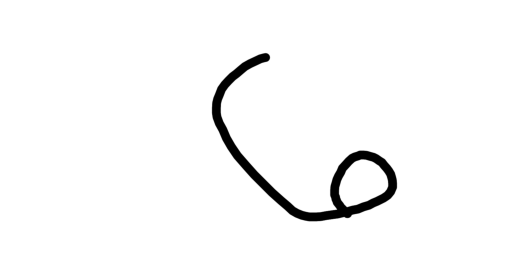

In [167]:
# Load & Display our own Handwritten Digit

img = plt.imread("../my_digit.png")

plt.imshow(img)
plt.axis("off")
plt.show()

In [168]:
# Inspect Image Properties

print("Image shape:", img.shape)
print("Data type:", img.dtype)
print("Minimum pixel value:", img.min())
print("Maximum pixel value:", img.max())

Image shape: (737, 1531, 4)
Data type: float32
Minimum pixel value: 0.0
Maximum pixel value: 1.0


In [169]:
# Convert Image to Grayscale
# (Got an error that's why we use "Pillow" library instead of "cv2")

# import cv2
# img_gray = cv2.imread("my_digit.png", cv2.IMREAD_GRAYSCALE)
# plt.imshow(img_gray, cmap="gray")
# plt.axis("off")
# plt.show()

In [170]:
# Testing 

from PIL import Image 

print("Pillow is installed!")

Pillow is installed!


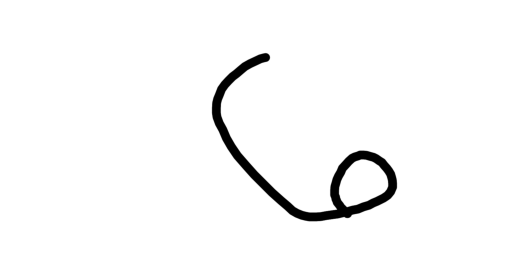

In [171]:
# Convert Image to Grayscale
# It gives an output not our expected output like black background and white digit!!

img_gray = Image.open("../my_digit.png").convert("L")

plt.imshow(img_gray, cmap="gray")
plt.axis("off")
plt.show()

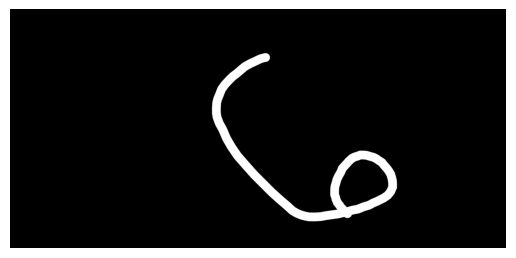

In [172]:
# Invert Image Colours

from PIL import ImageOps

img_inverted = ImageOps.invert(img_gray)

plt.imshow(img_inverted, cmap="gray")
plt.axis("off")
plt.show()

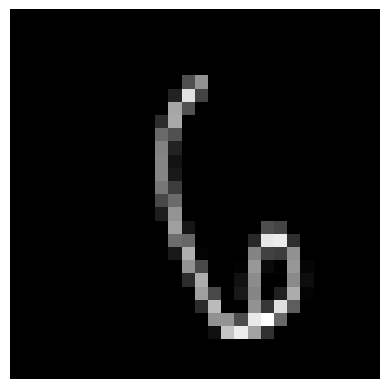

In [173]:
# Resize Image to 28*28 pixels

img_resized = img_inverted.resize((28,28))

plt.imshow(img_resized, cmap="gray")
plt.axis("off")
plt.show()

In [174]:
# Normalize Image Pixel Values

img_array = np.array(img_resized, dtype=np.float32)
img_normalized = img_array / 255.0

print("Minimum pixel value:", img_normalized.min())
print("Maximum pixel value:", img_normalized.max())

Minimum pixel value: 0.0
Maximum pixel value: 0.8627451


In [175]:
# Reshape Image for CNN Prediction

img_cnn = np.array(img_normalized).reshape(1, 28, 28, 1)
print("Image shape for CNN:", img_cnn.shape)

Image shape for CNN: (1, 28, 28, 1)


In [176]:
# Predict our own Handwritten digit

prediction = loaded_model.predict(img_cnn)
predicted_digit = np.argmax(prediction[0])
print("Predicted Digit:", predicted_digit)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step
Predicted Digit: 1


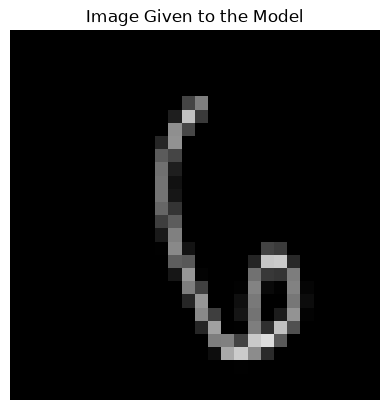

In [177]:
# Visualize prepared image before prediction

plt.imshow(img_cnn[0, :, :, 0], cmap="gray", vmin=0, vmax=1)
plt.title("Image Given to the Model")
plt.axis("off")
plt.show()

In [178]:
# In this experiment, the handwritten digit is cropped,
# inverted, resized while preserving its aspect ratio,
# centered on a 28x28 canvas, and normalized before prediction.

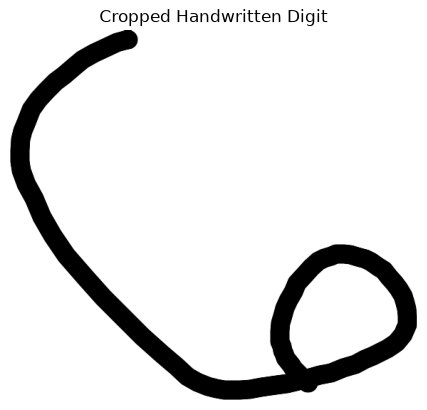

In [179]:
## Crop the handwritten digit 

gray_array = np.array(img_gray)

# Find pixels that belong to the black digit
digit_pixels = gray_array < 128

# Find the digit's boundries
rows = np.where(digit_pixels.any(axis=1))[0]
cols = np.where(digit_pixels.any(axis=0))[0]

# Crop around the digit
cropped_array = gray_array[
                           rows[0]:rows[-1] + 1,
                           cols[0]:cols[-1] + 1
                          ]

img_cropped = Image.fromarray(cropped_array)

plt.imshow(img_cropped, cmap="gray")
plt.title("Cropped Handwritten Digit")
plt.axis("off")
plt.show()

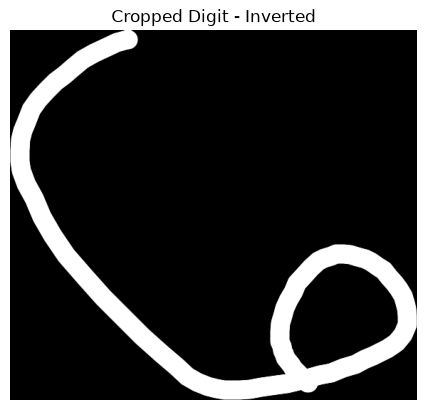

In [180]:
# Invert cropped image

img_cropped_inverted = ImageOps.invert(img_cropped)

plt.imshow(img_cropped_inverted, cmap="gray")
plt.title("Cropped Digit - Inverted")
plt.axis("off")
plt.show()

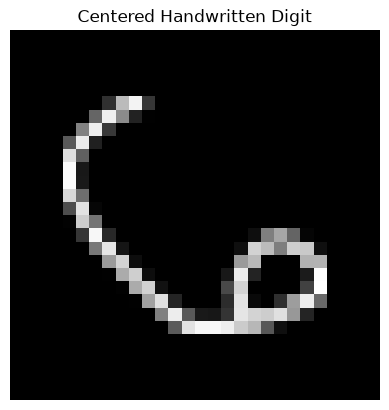

In [181]:
# Resize while preserving aspect ratio
img_fit = ImageOps.contain(img_cropped_inverted, (20, 20))

# Create a black 28x28 canvas
img_canvas = Image.new("L", (28, 28), 0)

# Center the digit on the canvas
position = (
    (28 - img_fit.width) // 2,
    (28 - img_fit.height) // 2
)
img_canvas.paste(img_fit, position)

# Display the prepared image
plt.imshow(img_canvas, cmap="gray")
plt.title("Centered Handwritten Digit")
plt.axis("off")
plt.show()

In [182]:
# Convert the centered image into a NumPy array
img_centered_array = np.array(img_canvas, dtype=np.float32)

# Normalize pixel values
img_centered_normalized = img_centered_array / 255.0

# Reshape for CNN prediction
img_centered_cnn = img_centered_normalized.reshape(1, 28, 28, 1)

print("Image shape:", img_centered_cnn.shape)
print("Minimum pixel value:", img_centered_normalized.min())
print("Maximum pixel value:", img_centered_normalized.max())

Image shape: (1, 28, 28, 1)
Minimum pixel value: 0.0
Maximum pixel value: 0.90588236


In [183]:
# Predict the centered handwritten digit
prediction_centered = loaded_model.predict(img_centered_cnn)

# Get the digit with the highest probability
predicted_centered_digit = np.argmax(prediction_centered[0])

print("Predicted Digit:", predicted_centered_digit)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
Predicted Digit: 6


In [184]:
# Analyze prediction probabilities
for digit, probability in enumerate(prediction_centered[0]):
    print(f"Digit {digit}: {probability * 100:.2f}%")

Digit 0: 3.42%
Digit 1: 0.19%
Digit 2: 20.70%
Digit 3: 0.03%
Digit 4: 0.03%
Digit 5: 0.34%
Digit 6: 75.14%
Digit 7: 0.02%
Digit 8: 0.11%
Digit 9: 0.03%


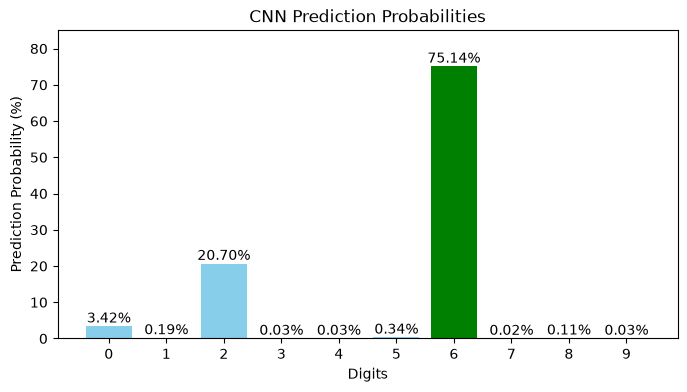

In [185]:
# Highlight the predicted digit
probabilities = prediction_centered[0] * 100

colors = [
    "green" if digit == predicted_centered_digit else "skyblue"
    for digit in range(10)
]

plt.figure(figsize=(8, 4))

plt.bar(range(10), probabilities, color=colors)

# Display percentage above each bar
for digit, probability in enumerate(probabilities):
    if probability > 0:
        plt.text(digit, probability + 1, f"{probability:.2f}%",
                 ha="center")

plt.xlabel("Digits")
plt.ylabel("Prediction Probability (%)")
plt.title("CNN Prediction Probabilities")
plt.xticks(range(10))
plt.ylim(0, 85)
plt.show()

In [186]:
# Load MNIST dataset for comparison
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

# Normalize training images
x_train_normalized = x_train / 255.0

# Find the first image of digit 6
mnist_six = np.where(y_train == 6)[0][0]

print("MNIST digit index:", mnist_six)
print("MNIST image shape:", x_train_normalized[mnist_six].shape)

MNIST digit index: 13
MNIST image shape: (28, 28)


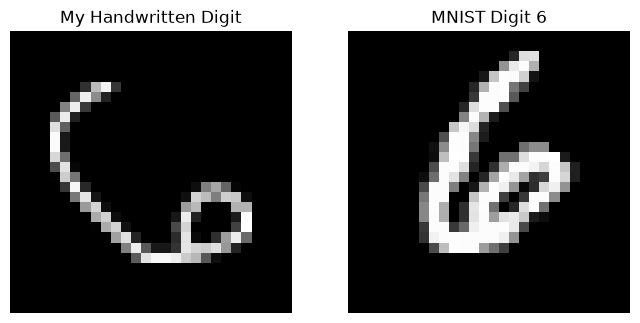

In [187]:
# Compare custom image with MNIST image

plt.figure(figsize=(8, 4))

## Our handwritten digit
plt.subplot(1, 2, 1)
plt.imshow(img_centered_cnn[0, :, :, 0], cmap="gray")
plt.title("My Handwritten Digit")
plt.axis("off")

## MNIST training digit
plt.subplot(1, 2, 2)
plt.imshow(x_train_normalized[mnist_six], cmap="gray")
plt.title("MNIST Digit 6")
plt.axis("off")

plt.show()